# Initial Findings: Accident Severity by Location & Weather
**Dataset:** US Accidents (March 2023 release), 500k-row sample
**Problem:** How do location and weather relate to accident severity?

**How to use this notebook:** run it top to bottom. Every step has:
- **What it shows**: why we run it
- **Record**: what to copy into the findings doc

The final step builds the **cleaning checklist** to hand to the next person.

| Step | Topic |
|---|---|
| 0 | Setup |
| 1 | Load the data |
| 2 | Shape & data types |
| 3 | Missing values & duplicates |
| 4 | Target: Severity |
| 5 | ⚠️ Severity by data source & year |
| 6 | Numeric columns: ranges & outliers |
| 7 | Categorical columns: cardinality & messy labels |
| 8 | Location: states, California, road type |
| 9 | Weather |
| 10 | Correlations with severity |
| 11 | Leakage check |
| 12 | Cleaning checklist (handoff) |

## Step 0: Setup
**What it shows:** nothing yet. It loads the libraries and a consistent chart style.
Colors used everywhere: **blue = Source1**, **orange = Source2**.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
BLUE, ORANGE, GRAY, LIGHT = "#2a78d6", "#eb6834", "#52514e", "#b4b2a9"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": GRAY, "xtick.color": GRAY,
    "ytick.color": GRAY, "axes.grid": True, "grid.color": "#ecebe7",
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
})

## Step 1: Load the data
**What it shows:** the raw file loads correctly. We keep `raw` untouched and work on a copy, `df`.

In [2]:
raw = pd.read_csv("US_Accidents_March23_sampled_500k.csv")
df = raw.copy()
df.head()

,ID,Source,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,End_Lat,End_Lng,Distance(mi),Description,Street,City,County,State,Zipcode,Country,Timezone,Airport_Code,Weather_Timestamp,Temperature(F),Wind_Chill(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Direction,Wind_Speed(mph),Precipitation(in),Weather_Condition,Amenity,Bump,Crossing,Give_Way,Junction,No_Exit,Railway,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop,Sunrise_Sunset,Civil_Twilight,Nautical_Twilight,Astronomical_Twilight
0,A-2047758,Source2,2,2019-06-12 10:10:56,2019-06-12 10:55:58,30.641211,-91.153481,NaN,NaN,0.000,Accident on LA-19 Baker-Zachary Hwy at Lower Z...,Highway 19,Zachary,East Baton Rouge,LA,70791-4610,US,US/Central,KBTR,2019-06-12 09:53:00,77.0,77.0,62.0,29.92,10.0,NW,5.0,0.0,Fair,False,False,False,False,False,False,False,False,False,False,False,True,False,Day,Day,Day,Day
1,A-4694324,Source1,2,2022-12-03 23:37:14.000000000,2022-12-04 01:56:53.000000000,38.990562,-77.399070,38.990037,-77.398282,0.056,Incident on FOREST RIDGE DR near PEPPERIDGE PL...,Forest Ridge Dr,Sterling,Loudoun,VA,20164-2813,US,US/Eastern,KIAD,2022-12-03 23:52:00,45.0,43.0,48.0,29.91,10.0,W,5.0,0.0,Fair,False,False,False,False,False,False,False,False,False,False,False,False,False,Night,Night,Night,Night
2,A-5006183,Source1,2,2022-08-20 13:13:00.000000000,2022-08-20 15:22:45.000000000,34.661189,-120.492822,34.661189,-120.492442,0.022,Accident on W Central Ave from Floradale Ave t...,Floradale Ave,Lompoc,Santa Barbara,CA,93436,US,US/Pacific,KLPC,2022-08-20 12:56:00,68.0,68.0,73.0,29.79,10.0,W,13.0,0.0,Fair,False,False,False,False,False,False,False,False,False,False,False,True,False,Day,Day,Day,Day
3,A-4237356,Source1,2,2022-02-21 17:43:04,2022-02-21 19:43:23,43.680592,-92.993317,43.680574,-92.972223,1.054,Incident on I-90 EB near REST AREA Drive with ...,14th St NW,Austin,Mower,MN,55912,US,US/Central,KAUM,2022-02-21 17:35:00,27.0,15.0,86.0,28.49,10.0,ENE,15.0,0.0,Wintry Mix,False,False,False,False,False,False,False,False,False,False,False,False,False,Day,Day,Day,Day
4,A-6690583,Source1,2,2020-12-04 01:46:00,2020-12-04 04:13:09,35.395484,-118.985176,35.395476,-118.985995,0.046,RP ADV THEY LOCATED SUSP VEH OF 20002 - 726 CR...,River Blvd,Bakersfield,Kern,CA,93305-2649,US,US/Pacific,KBFL,2020-12-04 01:54:00,42.0,42.0,34.0,29.77,10.0,CALM,0.0,0.0,Fair,False,False,False,False,False,False,False,False,False,False,False,False,False,Night,Night,Night,Night


## Step 2: Shape & data types
**What it shows:** how big the data is, what one row is (one accident), and whether each column has the right type.

**Record:** rows × columns, and any column whose type is wrong. In this file, `Start_Time` / `End_Time` load as text but should be datetimes, and `Zipcode` mixes 5-digit and 9-digit (ZIP+4) codes.

In [3]:
print(f"Rows: {df.shape[0]:,}   Columns: {df.shape[1]}")
print(f"Memory: {df.memory_usage(deep=True).sum() / 1e6:.0f} MB")
df.dtypes.value_counts()

Rows: 500,000   Columns: 46


Memory: 658 MB


str        20
bool       13
float64    12
int64       1
Name: count, dtype: int64

In [4]:
# One row per column: type, missing %, number of unique values, an example value
overview = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "missing_%": (df.isna().mean() * 100).round(1),
    "unique": df.nunique(),
    "example": df.iloc[0],
})
overview

,dtype,non_null,missing_%,unique,example
ID,str,500000,0.0,500000,A-2047758
Source,str,500000,0.0,3,Source2
Severity,int64,500000,0.0,4,2
Start_Time,str,500000,0.0,487027,2019-06-12 10:10:56
End_Time,str,500000,0.0,493821,2019-06-12 10:55:58
Start_Lat,float64,500000,0.0,368965,30.641211
Start_Lng,float64,500000,0.0,370195,-91.153481
End_Lat,float64,279623,44.1,220333,NaN
End_Lng,float64,279623,44.1,221463,NaN
Distance(mi),float64,500000,0.0,10627,0.0


In [5]:
# Fix the date columns (some have extra nanosecond digits, so cut them to 19 characters)
for c in ["Start_Time", "End_Time", "Weather_Timestamp"]:
    df[c] = pd.to_datetime(df[c].astype(str).str[:19], errors="coerce")
df["Year"]  = df["Start_Time"].dt.year
df["Month"] = df["Start_Time"].dt.month
df["Hour"]  = df["Start_Time"].dt.hour
df["Zip5"]  = df["Zipcode"].str[:5]
print("Date range:", df["Start_Time"].min(), "→", df["Start_Time"].max())
print("Unparseable Start_Time:", df["Start_Time"].isna().sum())
print("Zipcode lengths:", df["Zipcode"].str.len().value_counts().to_dict())

Date range: 2016-01-14 20:18:33 → 2023-03-31 22:46:13
Unparseable Start_Time: 0
Zipcode lengths: {5.0: 353426, 10.0: 146458}


## Step 3: Missing values & duplicates
**What it shows:** which columns are incomplete, and whether any accident is counted twice.

**Record:** columns with >20% missing (candidates to drop or flag) and columns with a few % missing (candidates to impute). Also check *where* the missing values are: here they depend on `Source`.

Duplicate rows: 0 | Duplicate IDs: 0


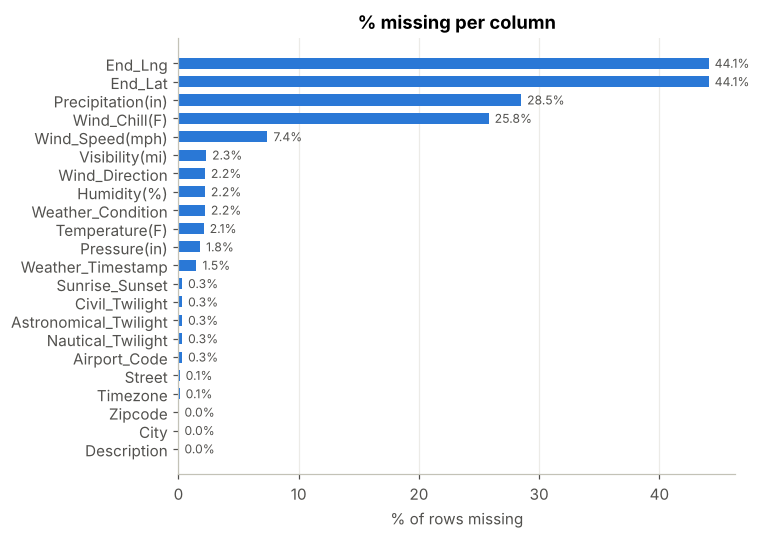

In [6]:
print("Duplicate rows:", df.duplicated().sum(), "| Duplicate IDs:", df["ID"].duplicated().sum())
missing = (raw.isna().mean() * 100).sort_values(ascending=False)
missing = missing[missing > 0].round(1)

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(missing.index[::-1], missing.values[::-1], color=BLUE, height=0.6)
for i, v in enumerate(missing.values[::-1]):
    ax.text(v + 0.5, i, f"{v}%", va="center", fontsize=8, color=GRAY)
ax.set_title("% missing per column"); ax.set_xlabel("% of rows missing"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

In [7]:
# Is missingness tied to the data source? (yes: End_Lat/Lng are missing for every Source2 row)
(raw.groupby("Source")[["End_Lat", "Precipitation(in)", "Wind_Chill(F)", "Wind_Speed(mph)", "Weather_Condition"]]
    .apply(lambda g: g.isna().mean() * 100).round(1))

,End_Lat,Precipitation(in),Wind_Chill(F),Wind_Speed(mph),Weather_Condition
Source,,,,,
Source1,0.0,14.4,12.3,4.7,2.5
Source2,100.0,47.1,43.5,10.9,1.9
Source3,100.0,25.7,21.5,6.3,1.7


## Step 4: The target: Severity
**What it shows:** how severity is distributed. Severity (1–4) measures **impact on traffic (delay length)**, *not* injuries.

**Record:** the % in each level. The data is imbalanced (80% is level 2), so we create a binary target: **High_Sev = Severity 3 or 4**.

,count,%
Severity,,
1,4274,0.85
2,398142,79.63
3,84520,16.90
4,13064,2.61


High severity (3–4): 19.5%


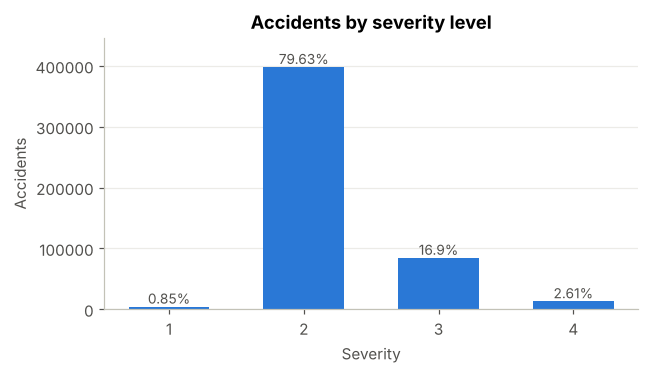

In [8]:
df["High_Sev"] = (df["Severity"] >= 3).astype(int)
sev = df["Severity"].value_counts().sort_index()
sev_pct = (sev / len(df) * 100).round(2)
display(pd.DataFrame({"count": sev, "%": sev_pct}))
print(f"High severity (3–4): {df['High_Sev'].mean()*100:.1f}%")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(sev.index.astype(str), sev.values, color=BLUE, width=0.6)
for x, (c, p) in enumerate(zip(sev.values, sev_pct.values)):
    ax.text(x, c + 5000, f"{p}%", ha="center", fontsize=9, color=GRAY)
ax.set_ylim(0, sev.max() * 1.12)
ax.set_title("Accidents by severity level"); ax.set_xlabel("Severity"); ax.set_ylabel("Accidents")
ax.grid(axis="x", visible=False); plt.tight_layout(); plt.show()

## Step 5: ⚠️ Severity by data source & year (most important check)
**What it shows:** the dataset merges different data providers (`Source`), and **each one labels severity differently**. The provider mix also changes over the years.

**Record:** the % high severity per source, and the line chart. **Decision for the team:** analyze Source2 only (stable over time), or always split results by source.

In [9]:
print(df["Source"].value_counts())
(pd.crosstab(df["Source"], df["Severity"], normalize="index") * 100).round(1)

Source
Source1    279623
Source2    214044
Source3      6333
Name: count, dtype: int64


Severity,1,2,3,4
Source,,,,
Source1,0.6,91.2,3.8,4.3
Source2,1.0,64.9,33.6,0.4
Source3,4.4,64.7,30.8,0.1


In [ ]:
(pd.crosstab(df["Year"], df["Severity"], normalize="index") * 100).round(1)

Severity,1,2,3,4
Year,,,,
2016,0.1,65.9,30.7,3.3
2017,0.0,64.2,32.4,3.3
2018,0.0,64.4,32.8,2.8
2019,0.0,71.9,25.1,3.0
2020,2.4,79.1,15.8,2.7
2021,0.0,88.6,9.5,1.9
2022,2.1,91.0,4.5,2.4
2023,0.0,97.0,0.0,3.0


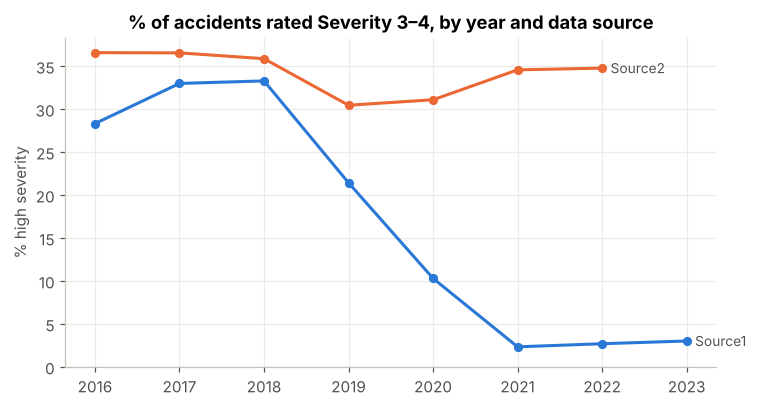

In [11]:
yr = df[df["Source"].isin(["Source1", "Source2"])].groupby(["Year", "Source"])["High_Sev"].mean().unstack() * 100
fig, ax = plt.subplots(figsize=(7, 3.8))
for src, col in [("Source1", BLUE), ("Source2", ORANGE)]:
    s = yr[src].dropna()
    ax.plot(s.index, s.values, color=col, lw=2, marker="o", ms=5)
    ax.text(s.index[-1] + 0.1, s.values[-1], src, color=GRAY, va="center", fontsize=9)
ax.set_title("% of accidents rated Severity 3–4, by year and data source")
ax.set_ylabel("% high severity"); ax.set_ylim(0, None); plt.tight_layout(); plt.show()

## Step 6: Numeric columns: ranges & outliers
**What it shows:** impossible or extreme values that must be fixed before correlations or modeling.

**Record:** any value outside a realistic range. In this file: temperatures up to 207°F, wind speeds up to 822 mph, visibility up to 130 mi, and pressure as low as 0.12 in. (Pressure down to ~24 in is real: it is station pressure in high-altitude states like CO and UT, so the cutoff is 20.)

In [12]:
num_cols = ["Temperature(F)", "Wind_Chill(F)", "Humidity(%)", "Pressure(in)",
            "Visibility(mi)", "Wind_Speed(mph)", "Precipitation(in)", "Distance(mi)"]
df[num_cols].describe(percentiles=[.01, .5, .99]).T.round(2)

,count,mean,std,min,1%,50%,99%,max
Temperature(F),489534.0,61.65,19.00,-77.80,12.00,64.00,96.00,207.00
Wind_Chill(F),370983.0,58.23,22.35,-53.20,-2.00,62.00,95.00,207.00
Humidity(%),488870.0,64.83,22.83,1.00,12.00,67.00,100.00,100.00
Pressure(in),491072.0,29.54,1.01,0.12,24.56,29.86,30.44,38.44
Visibility(mi),488709.0,9.09,2.71,0.00,0.50,10.00,10.00,130.00
Wind_Speed(mph),463013.0,7.68,5.43,0.00,0.00,7.00,23.00,822.80
Precipitation(in),357384.0,0.01,0.10,0.00,0.00,0.00,0.18,10.13
Distance(mi),500000.0,0.56,1.77,0.00,0.00,0.03,7.01,193.48


In [13]:
# Realistic ranges: values outside these are treated as errors
valid_range = {
    "Temperature(F)": (-40, 130), "Wind_Chill(F)": (-60, 130), "Humidity(%)": (0, 100),
    "Pressure(in)": (20, 32), "Visibility(mi)": (0, 50), "Wind_Speed(mph)": (0, 100),
    "Precipitation(in)": (0, 5),
}
out = pd.DataFrame({c: {"below_min": (df[c] < lo).sum(), "above_max": (df[c] > hi).sum(),
                        "range_used": f"{lo} to {hi}"} for c, (lo, hi) in valid_range.items()}).T
out

,below_min,above_max,range_used
Temperature(F),1,3,-40 to 130
Wind_Chill(F),0,3,-60 to 130
Humidity(%),0,0,0 to 100
Pressure(in),23,1,20 to 32
Visibility(mi),0,74,0 to 50
Wind_Speed(mph),0,7,0 to 100
Precipitation(in),0,29,0 to 5


/tmp/ipykernel_377/1226784899.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df[c].dropna(), vert=False, widths=0.5, patch_artist=True,
/tmp/ipykernel_377/1226784899.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df[c].dropna(), vert=False, widths=0.5, patch_artist=True,
/tmp/ipykernel_377/1226784899.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df[c].dropna(), vert=False, widths=0.5, patch_artist=True,
/tmp/ipykernel_377/1226784899.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot

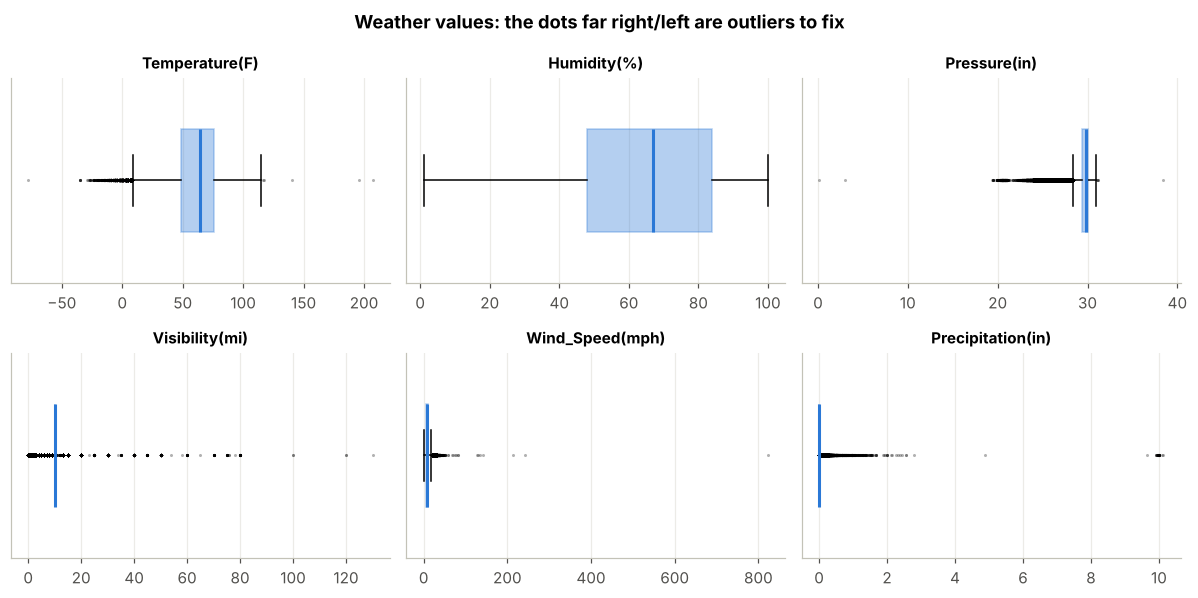

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(11, 5.5))
for ax, c in zip(axes.flat, ["Temperature(F)", "Humidity(%)", "Pressure(in)",
                             "Visibility(mi)", "Wind_Speed(mph)", "Precipitation(in)"]):
    ax.boxplot(df[c].dropna(), vert=False, widths=0.5, patch_artist=True,
               boxprops=dict(facecolor=BLUE, alpha=0.35, color=BLUE),
               medianprops=dict(color=BLUE, lw=2), flierprops=dict(marker=".", ms=2, alpha=0.3, color=GRAY))
    ax.set_title(c, fontsize=10); ax.set_yticks([])
fig.suptitle("Weather values: the dots far right/left are outliers to fix", fontweight="bold")
plt.tight_layout(); plt.show()

## Step 7: Categorical columns: cardinality & messy labels
**What it shows:** how many distinct values each text column has, whether any column is constant (useless), and whether some labels mean the same thing.

**Record:** constant columns (drop), very high-cardinality columns (don't one-hot encode), and duplicate labels (e.g. `Calm` vs `CALM`, `Variable` vs `VAR`).

In [15]:
cat_cols = df.select_dtypes(include=["object", "string", "bool"]).columns
card = df[cat_cols].nunique().sort_values()
card.to_frame("unique_values")

,unique_values
Country,1
Turning_Loop,1
Crossing,2
Amenity,2
Civil_Twilight,2
Sunrise_Sunset,2
Traffic_Signal,2
Bump,2
Railway,2
Stop,2


In [16]:
print("Constant columns:", list(card[card <= 1].index))
print("\nWind_Direction labels:", sorted(df["Wind_Direction"].dropna().unique()))
print("\nWeather_Condition: top 20 of", df["Weather_Condition"].nunique())
df["Weather_Condition"].value_counts().head(20)

Constant columns: ['Country', 'Turning_Loop']

Wind_Direction labels: ['CALM', 'Calm', 'E', 'ENE', 'ESE', 'East', 'N', 'NE', 'NNE', 'NNW', 'NW', 'North', 'S', 'SE', 'SSE', 'SSW', 'SW', 'South', 'VAR', 'Variable', 'W', 'WNW', 'WSW', 'West']

Weather_Condition: top 20 of 108


Weather_Condition
Fair                       166053
Mostly Cloudy               65398
Cloudy                      53107
Clear                       52379
Partly Cloudy               45125
Overcast                    24901
Light Rain                  22718
Scattered Clouds            13030
Light Snow                   8233
Fog                          6445
Rain                         5501
Haze                         4967
Fair / Windy                 2361
Heavy Rain                   2133
Light Drizzle                1474
Thunder in the Vicinity      1186
Mostly Cloudy / Windy        1123
Cloudy / Windy               1080
T-Storm                      1052
Snow                          982
Name: count, dtype: int64

In [17]:
# Boolean road features: how common is each? (rare ones carry little signal)
road_cols = ["Amenity", "Bump", "Crossing", "Give_Way", "Junction", "No_Exit", "Railway",
             "Roundabout", "Station", "Stop", "Traffic_Calming", "Traffic_Signal", "Turning_Loop"]
(df[road_cols].mean() * 100).sort_values(ascending=False).round(2).to_frame("% of accidents")

,% of accidents
Traffic_Signal,14.81
Crossing,11.25
Junction,7.40
Stop,2.81
Station,2.60
Amenity,1.24
Railway,0.86
Give_Way,0.47
No_Exit,0.25
Traffic_Calming,0.09


## Step 8: Location: states, California, road type
**What it shows:** where the data is concentrated (the California question) and how severity varies by place.

**Record:** CA's share of the data, the source mix per state (raw state rankings are biased by it), the CA county ranking, and the highway vs non-highway gap.

In [18]:
state = df.groupby("State").agg(accidents=("ID", "size"), pct_high_sev=("High_Sev", "mean"))
state["share_of_data_%"] = state["accidents"] / len(df) * 100
state["pct_high_sev"] *= 100
state.sort_values("accidents", ascending=False).head(15).round(1)

,accidents,pct_high_sev,share_of_data_%
State,,,
CA,113274,16.4,22.7
FL,56710,13.3,11.3
TX,37355,21.9,7.5
SC,24737,11.9,4.9
NY,22594,23.3,4.5
NC,21750,11.7,4.4
VA,19515,23.0,3.9
PA,19351,15.7,3.9
MN,12333,16.4,2.5


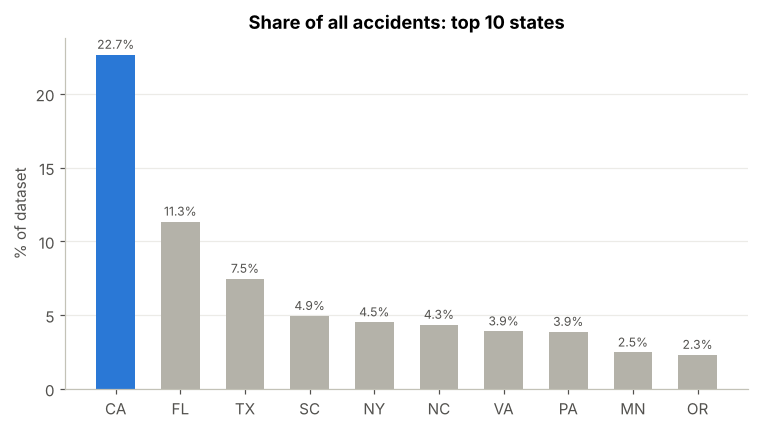

In [19]:
top = state.sort_values("accidents", ascending=False).head(10)
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(top.index, top["share_of_data_%"], color=[BLUE if s == "CA" else LIGHT for s in top.index], width=0.6)
for x, v in enumerate(top["share_of_data_%"]):
    ax.text(x, v + 0.4, f"{v:.1f}%", ha="center", fontsize=8, color=GRAY)
ax.set_title("Share of all accidents: top 10 states"); ax.set_ylabel("% of dataset")
ax.grid(axis="x", visible=False); plt.tight_layout(); plt.show()

In [20]:
# Source mix per state: why raw state comparisons are misleading
(pd.crosstab(df["State"], df["Source"], normalize="index") * 100).loc[["CA", "FL", "TX", "GA", "IL", "NY", "VA"]].round(0)

Source,Source1,Source2,Source3
State,,,
CA,63.0,34.0,3.0
FL,68.0,32.0,1.0
TX,38.0,61.0,1.0
GA,45.0,55.0,1.0
IL,40.0,59.0,1.0
NY,56.0,43.0,1.0
VA,67.0,33.0,0.0


In [21]:
# Fairer state ranking: within Source2 only, states with >= 2,000 accidents
s2 = df[df["Source"] == "Source2"]
t = s2.groupby("State").agg(n=("ID", "size"), pct_high_sev=("High_Sev", "mean")).query("n >= 2000")
t["pct_high_sev"] *= 100
t.sort_values("pct_high_sev", ascending=False).round(1)

,n,pct_high_sev
State,,
MO,2060,69.4
GA,6080,59.5
VA,6348,49.0
MD,2701,48.5
MN,3789,45.6
IN,2067,43.4
OH,4624,40.5
NY,9717,40.1
CA,38222,40.0


CA accidents: 113,274  |  CA Source2: 38,222


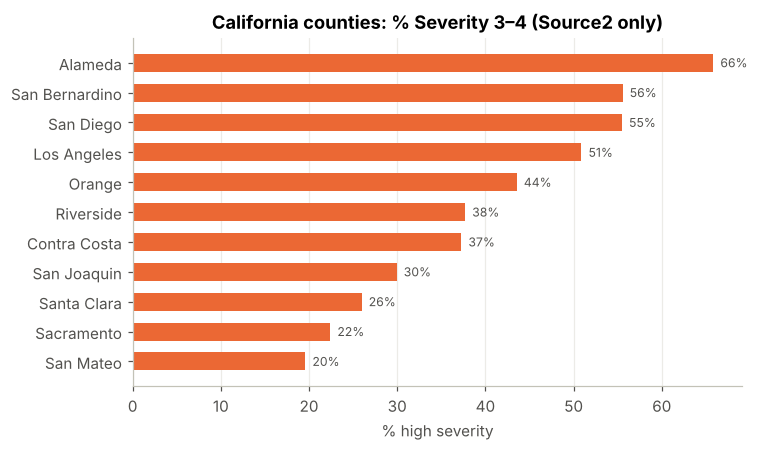

In [22]:
# California drill-down by county (Source2 only, counties with >= 700 accidents)
ca = df[df["State"] == "CA"]
print(f"CA accidents: {len(ca):,}  |  CA Source2: {(ca['Source']=='Source2').sum():,}")
cty = (ca[ca["Source"] == "Source2"].groupby("County")
       .agg(n=("ID", "size"), pct_high_sev=("High_Sev", "mean")).query("n >= 700"))
cty["pct_high_sev"] *= 100
cty = cty.sort_values("pct_high_sev")
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(cty.index, cty["pct_high_sev"], color=ORANGE, height=0.6)
for i, v in enumerate(cty["pct_high_sev"]):
    ax.text(v + 0.8, i, f"{v:.0f}%", va="center", fontsize=8, color=GRAY)
ax.set_title("California counties: % Severity 3–4 (Source2 only)"); ax.set_xlabel("% high severity")
ax.grid(axis="y", visible=False); plt.tight_layout(); plt.show()

In [23]:
# Road type: flag highways from the street name
st = df["Street"].fillna("").str.upper()
df["Is_Highway"] = st.str.contains(r"\bI-|INTERSTATE|\bHWY\b|HIGHWAY|FWY|FREEWAY|EXPY|EXPRESSWAY|\bUS-|\bSR-|TURNPIKE|PKWY", regex=True).astype(int)
print(f"Highway share of accidents: {df['Is_Highway'].mean()*100:.1f}%")
(df.groupby(["Source", "Is_Highway"])["High_Sev"].mean().unstack() * 100).round(1)

Highway share of accidents: 43.8%


Is_Highway,0,1
Source,,
Source1,6.9,9.4
Source2,17.8,60.3
Source3,13.9,53.7


## Step 9: Weather
**What it shows:** whether bad weather goes with more severe accidents. 108 raw labels are grouped into 6 categories, and we compare **within each source**.

**Record:** the high-severity % per weather group (Source2), and how many accidents happen in each weather type.

In [24]:
def weather_group(w):
    if pd.isna(w): return "Unknown"
    w = w.lower()
    if "thunder" in w or "t-storm" in w: return "Thunderstorm"
    if any(k in w for k in ["snow", "sleet", "ice", "freezing", "wintry", "hail"]): return "Snow/Ice"
    if any(k in w for k in ["rain", "drizzle", "shower"]): return "Rain"
    if any(k in w for k in ["fog", "mist", "haze", "smoke", "dust"]): return "Fog/Low vis"
    if "cloud" in w or "overcast" in w: return "Cloudy"
    if "fair" in w or "clear" in w: return "Clear/Fair"
    return "Other"
df["Weather_Group"] = df["Weather_Condition"].map(weather_group)
(df["Weather_Group"].value_counts(normalize=True) * 100).round(1).to_frame("% of accidents")

,% of accidents
Weather_Group,
Clear/Fair,44.2
Cloudy,40.9
Rain,6.6
Fog/Low vis,2.6
Snow/Ice,2.3
Unknown,2.2
Thunderstorm,1.1
Other,0.0


Source,Source1,Source2
Weather_Group,,
Fog/Low vis,6.1,30.3
Clear/Fair,6.9,32.1
Cloudy,9.6,34.5
Rain,9.1,38.5
Thunderstorm,7.0,42.9
Snow/Ice,7.5,43.6


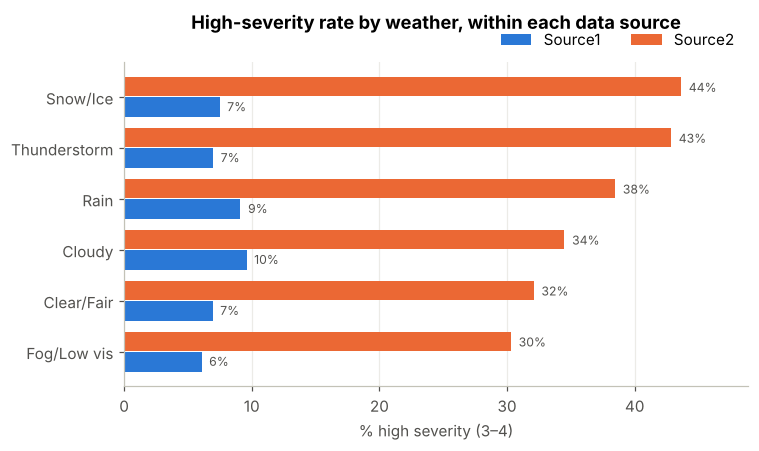

In [25]:
wx = (df[df["Source"].isin(["Source1", "Source2"]) & ~df["Weather_Group"].isin(["Other", "Unknown"])]
      .groupby(["Weather_Group", "Source"])["High_Sev"].mean().unstack() * 100).sort_values("Source2")
display(wx.round(1))
y = np.arange(len(wx)); h = 0.38
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(y - h/2 - 0.01, wx["Source1"], height=h, color=BLUE, label="Source1")
ax.barh(y + h/2 + 0.01, wx["Source2"], height=h, color=ORANGE, label="Source2")
for i, (a, b) in enumerate(zip(wx["Source1"], wx["Source2"])):
    ax.text(b + 0.6, i + h/2, f"{b:.0f}%", va="center", fontsize=8, color=GRAY)
    ax.text(a + 0.6, i - h/2, f"{a:.0f}%", va="center", fontsize=8, color=GRAY)
ax.set_yticks(y, wx.index); ax.set_xlabel("% high severity (3–4)"); ax.set_xlim(0, wx.values.max() * 1.12)
ax.set_title("High-severity rate by weather, within each data source", pad=22)
ax.legend(frameon=False, loc="lower right", bbox_to_anchor=(1, 1.0), ncol=2); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

In [26]:
# Numeric weather, binned (Source2)
s2 = df[df["Source"] == "Source2"].copy()
s2["Visibility"]  = pd.cut(s2["Visibility(mi)"], [-1, 1, 3, 5, 9.99, 1e9], labels=["<=1", "1-3", "3-5", "5-10", "10+"])
s2["Temperature"] = pd.cut(s2["Temperature(F)"], [-100, 32, 50, 70, 85, 300], labels=["<=32", "32-50", "50-70", "70-85", "85+"])
s2["Any_Precip"]  = s2["Precipitation(in)"] > 0
for c in ["Visibility", "Temperature", "Any_Precip", "Sunrise_Sunset"]:
    print(f"\n% high severity by {c} (Source2)")
    display((s2.groupby(c, observed=True)["High_Sev"].agg(["mean", "size"])
             .assign(mean=lambda d: (d["mean"] * 100).round(1)).rename(columns={"mean": "% high", "size": "n"})))


% high severity by Visibility (Source2)


,% high,n
Visibility,,
<=1,33.8,5161
1-3,36.8,8492
3-5,34.9,7657
5-10,33.3,20619
10+,33.8,168033



% high severity by Temperature (Source2)


,% high,n
Temperature,,
<=32,36.8,15344
32-50,32.4,38387
50-70,34.0,76621
70-85,34.6,61379
85+,32.4,18693



% high severity by Any_Precip (Source2)


,% high,n
Any_Precip,,
False,33.6,199234
True,40.7,14810



% high severity by Sunrise_Sunset (Source2)


,% high,n
Sunrise_Sunset,,
Day,33.2,158079
Night,36.6,55865


## Step 10: Correlations with severity
**What it shows:** which numeric and yes/no features move with high severity, and which features are redundant with each other. It uses Source2 only, so the provider effect doesn't distort the results.

**Record:** the top features correlated with `High_Sev`, and pairs of features that are highly correlated with each other (e.g. Temperature and Wind_Chill: keep one).

*Correlations here are weak by nature (binary target). Use them to rank features, not to prove cause.*

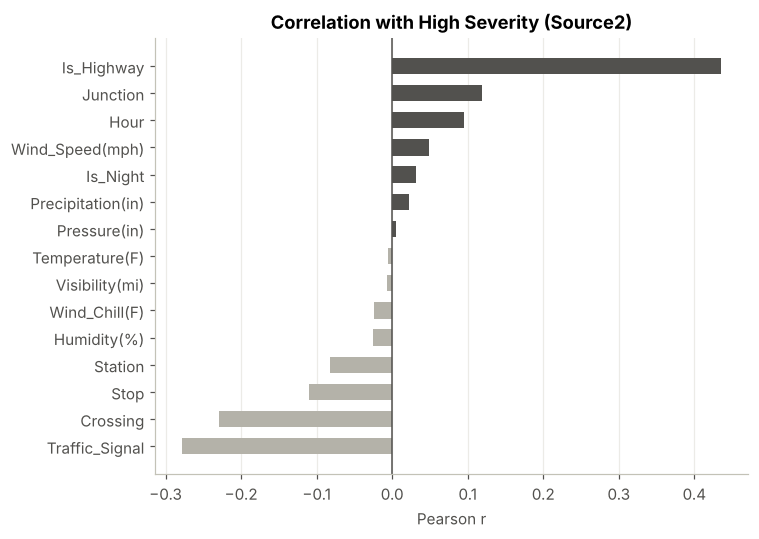

In [27]:
s2 = df[df["Source"] == "Source2"].copy()
s2["Is_Night"] = (s2["Sunrise_Sunset"] == "Night").astype(int)
feat = ["Temperature(F)", "Wind_Chill(F)", "Humidity(%)", "Pressure(in)", "Visibility(mi)",
        "Wind_Speed(mph)", "Precipitation(in)", "Is_Highway", "Is_Night", "Hour",
        "Junction", "Traffic_Signal", "Crossing", "Stop", "Station"]
corr = s2[feat + ["High_Sev"]].astype(float).corr()
target_corr = corr["High_Sev"].drop("High_Sev").sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(target_corr.index, target_corr.values, color=[GRAY if v > 0 else LIGHT for v in target_corr.values], height=0.6)
ax.axvline(0, color=GRAY, lw=1)
ax.set_title("Correlation with High Severity (Source2)"); ax.set_xlabel("Pearson r")
ax.grid(axis="y", visible=False); plt.tight_layout(); plt.show()

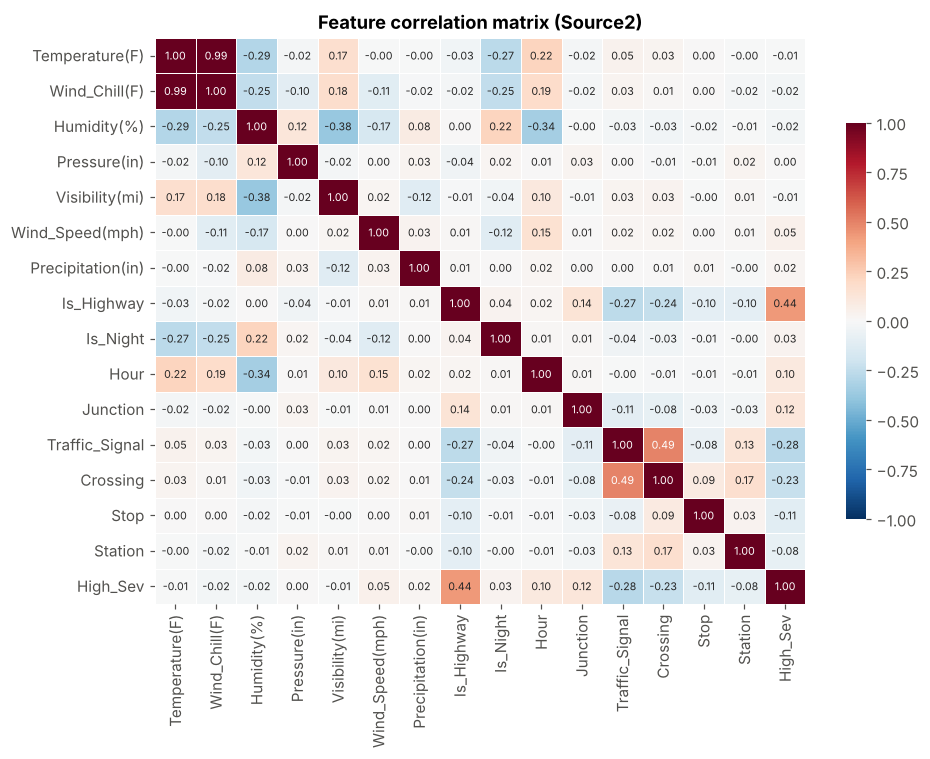

In [28]:
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 7}, linewidths=0.5, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Feature correlation matrix (Source2)"); plt.tight_layout(); plt.show()

## Step 11: Leakage check
**What it shows:** columns that are only known *after* the accident is cleared. They partly *reflect* severity, so a model that uses them would look great but be useless in practice.

**Record:** exclude `End_Time` (duration), `End_Lat/Lng`, `Distance(mi)` and `Description` from the predictors.

In [29]:
df["Duration_min"] = (df["End_Time"] - df["Start_Time"]).dt.total_seconds() / 60
display(df.groupby("Severity")[["Duration_min", "Distance(mi)"]].median().round(1))
print("Description mentions 'closed' → % high severity:")
print((df.groupby(df["Description"].str.contains("closed", case=False, na=False))["High_Sev"].mean() * 100).round(1))

,Duration_min,Distance(mi)
Severity,,
1,44.8,0.0
2,77.6,0.1
3,44.4,0.0
4,129.2,0.5


Description mentions 'closed' → % high severity:


Description
False    17.5
True     46.0
Name: High_Sev, dtype: float64


## Step 12: Cleaning checklist (handoff)
**What it shows:** one table, built from the steps above, listing every column that needs handling before visualizations, correlations and the ML model. It is saved as `cleaning_checklist.csv` for the next person.

In [30]:
rows = []
# Missing data (from Step 3)
for c, p in missing.items():
    if p > 40:   action = "Drop column"
    elif p > 20: action = "Drop, or add a missing-flag + impute"
    else:        action = "Impute (median for numbers, 'Unknown' for text) or drop rows"
    rows.append((c, "Missing values", f"{p}% missing", action))
# Outliers (from Step 6)
for c, r in out.iterrows():
    n = int(r["below_min"] + r["above_max"])
    if n: rows.append((c, "Impossible values", f"{n:,} rows outside {r['range_used']}", "Set to NaN, then impute"))
# Types & labels (Steps 2 and 7)
rows += [
    ("Start_Time / End_Time / Weather_Timestamp", "Wrong type (text)", "Extra nanosecond digits", "Cut to 19 chars → to_datetime"),
    ("Zipcode", "Mixed format", "5-digit and ZIP+4", "Keep first 5 digits (Zip5)"),
    ("Wind_Direction", "Duplicate labels", "Calm/CALM, Variable/VAR, North/N…", "Map to one label set"),
    ("Weather_Condition", "Too many labels", f"{df['Weather_Condition'].nunique()} unique", "Use Weather_Group (6 groups + Unknown)"),
    ("Street", "Signal hidden in text", "Highway names", "Create Is_Highway flag"),
    ("Civil/Nautical/Astronomical_Twilight", "Redundant", "Near-copies of Sunrise_Sunset", "Keep Sunrise_Sunset only"),
]
for c in card[card <= 1].index:
    rows.append((c, "Constant column", "1 unique value", "Drop"))
# Target & leakage (Steps 4, 5, 11)
rows += [
    ("Severity", "Inconsistent between sources", "Source1 8% vs Source2 34% high", "Use Source2 only or split by Source; target High_Sev = 3–4"),
    ("Severity", "Class imbalance", f"{df['High_Sev'].mean()*100:.1f}% high", "Stratified split; class weights"),
    ("End_Time, End_Lat/Lng, Distance(mi), Description", "Leakage", "Known only after the accident", "Exclude from predictors"),
    ("ID, Source", "Not predictive", "Identifier / provider", "Exclude from predictors (use Source only to filter)"),
]
checklist = pd.DataFrame(rows, columns=["Column", "Issue", "Evidence", "Action"])
checklist.to_csv("cleaning_checklist.csv", index=False)
checklist

,Column,Issue,Evidence,Action
0,End_Lng,Missing values,44.1% missing,Drop column
1,End_Lat,Missing values,44.1% missing,Drop column
2,Precipitation(in),Missing values,28.5% missing,"Drop, or add a missing-flag + impute"
3,Wind_Chill(F),Missing values,25.8% missing,"Drop, or add a missing-flag + impute"
4,Wind_Speed(mph),Missing values,7.4% missing,"Impute (median for numbers, 'Unknown' for text..."
5,Visibility(mi),Missing values,2.3% missing,"Impute (median for numbers, 'Unknown' for text..."
6,Wind_Direction,Missing values,2.2% missing,"Impute (median for numbers, 'Unknown' for text..."
7,Humidity(%),Missing values,2.2% missing,"Impute (median for numbers, 'Unknown' for text..."
8,Weather_Condition,Missing values,2.2% missing,"Impute (median for numbers, 'Unknown' for text..."
9,Temperature(F),Missing values,2.1% missing,"Impute (median for numbers, 'Unknown' for text..."
